In [67]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator

from typing import Union, List

import frb_functions

In [4]:
def gaus(x,a,x0,sigma,d):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))+d

In [63]:
def waterfaller_maker(burst, DM, dededisp=None):
    
    #Define the figure
    fig5 = plt.figure(figsize=(10,10))
    
    #Width 0.1 is for the hidden axes
    widths = [1]
    heights = [1, 2.5]
    spec5 = fig5.add_gridspec(ncols=1, nrows=2, width_ratios=widths, height_ratios=heights,\
                              wspace=0.25, hspace=0.0)

    ###################################
    burst = your.Your(burst_list[0])

    header_dict = frb_functions.your_header_to_dict(burst)

    tsamp = header_dict["tsamp"]
    nbins = header_dict["nspectra"]
    fsamp = header_dict["foff"] * -1
    
    tmin = 0.0
    tmax = nbins * burst.tsamp # seconds
    fmin = header_dict["fmin"]
    fmax = header_dict["fmax"]
    extent_b = [tmin, tmax, fmin, fmax]

    offset = 0.3398
    extent_b[0] = (tmin - offset) * 1000
    extent_b[1] = (tmax - offset) * 1000
    print(f"the extent of the data is: {extent_b}")
    
    #time increasing, freq decreasing
    print("loading in the data")
    d = frb_functions.get_data(burst,nstart=0, nsamp=nbins, npoln=1)

    freqs = header_dict["freqs"] # in Mhz

    if dededisp != None:
        print(f"de-de-dispersing to DM zero using {dededisp} pc/cc")
        d = frb_functions.dedisperse(d,dededisp,freqs,tsamp)
        
    dm_dedisp = DM
    print(f"de-dispersing to {dm_dedisp} pc/cc")
    stokes_i = frb_functions.dedisperse(d,dm_dedisp,freqs,tsamp)

    print(f"Correcting for the bandpass")
    stokes_i = frb_functions.correct_bandpass(stokes_i)

    downsamp_t = 1
    downsamp_f = 1
    print(f"downsample factors are: time:{downsamp_t} and freq:{downsamp_f}")
    if downsamp_f > 1 or downsamp_t > 1:
        print(f"running downsampling and correcting bandpass")
        stokes_i = frb_functions.downsample(stokes_i, freqf=downsamp_f, timef=downsamp_t)
        tsamp = tsamp * downsamp_t
        fsamp = fsamp * downsamp_f
        stokes_i = frb_functions.correct_bandpass(stokes_i)
        downsamp_flag = True
    else:
        downsamp_flag = False

    #Masking Subband edges
    print(f"Masking subband edges")
    nchans = header_dict["nchans"]
    bw = header_dict["bw"] * -1
    subband_edges_arr = frb_functions.get_subband_edges(bandwidth=bw, n_chan=nchans)
    stokes_i = frb_functions.mask_array(stokes_i, subband_edges_arr)
                                        
    new_quantiles = np.nanpercentile(stokes_i.compressed(), (1.0, 99.9))
    
    #Create x grid to plot the step function. 
    x_grid = np.linspace(extent_b[0], extent_b[1], endpoint=False, num=stokes_i.shape[1])

    prof = np.mean(stokes_i,axis=0)
    stokes_i_normprof = frb_functions.normalize_1d(prof)
    
    ax2 = fig5.add_subplot(spec5[1, 0]) 
    ax2.imshow(stokes_i, aspect='auto', interpolation='None',\
          extent=extent_b, vmin=new_quantiles[0], vmax=new_quantiles[1])

    window_ms = 0.1
    ax2.set_xlim(-window_ms,window_ms)
    ax2.set_ylabel('Frequency (MHz)',size=25)
    ax2.set_xlabel('Time (ms)',size=25)
    ax2.yaxis.set_major_locator(ticker.LinearLocator(5))
    ax2.xaxis.set_minor_locator(ticker.MultipleLocator(10))
    
    ax1 = fig5.add_subplot(spec5[0, 0], sharex=ax2)
    ax1.set_ylabel('S/N',size=25)
    ax1.plot(x_grid, stokes_i_normprof, drawstyle='steps-post', color='black')

    # ax1.text(0.96, 0.93, "Westerbork RT-1", transform=ax1.transAxes, fontsize=24, va='top', ha='right')
    # #ax1.text(-28,12, f"DM = 219.37" + r" pc cm$^{-3}$", fontsize=18)
    
    #Ticks on the SN-
    maxSN = np.ceil(np.max(stokes_i_normprof))
    yticks_sn=np.array([0,int(maxSN/2),int(maxSN)])
    ax1.set_yticks(yticks_sn)
    #ax1.yaxis.set_minor_locator(ticker.LinearLocator(3))
    ax1.set_ylim(-100,maxSN+30)

    ax1.text(0.04, 0.93, fr"$\Delta$t  = {(tsamp*1e6):.0f} $\mu$s" + "\n" + fr"$\Delta \nu$  = {(fsamp*1e3):.0f} kHz " + "\n" + \
             fr"DM = {DM:.2f}"+ r" pc cm$^{-3}$", transform=ax1.transAxes, fontsize=20, va='top', ha='left')
    
    ###################################
    
    #Setting labels and ticks 
    for ax in [ax1,ax2]:
        
        ax.tick_params(labelsize=22) 
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
    
    for ax in [ax1]:
        
        ax.tick_params(labelbottom=False)
        ax.tick_params(axis='x', which='major', direction='in', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='in', length=5, width=2)

    
    plot_name = header_dict["basename"] + f"_{(2*window_ms)}ms"

    if downsamp_flag == True:
        plot_name = header_dict["basename"] + f"_{(2*window_ms)}ms" + f"_{(tsamp*1e6):.0f}us_" + f"{(fsamp*1e3):.0f}kHz"
    print(f"plot_name: {plot_name}")
    fig5.savefig(plot_name + ".pdf", dpi=600, bbox_inches='tight')
    # fig5.savefig(plot_name + ".png", facecolor='white', \
    #         transparent=False, format = 'png',bbox_inches='tight', dpi=600)
    
    return

the extent of the data is: [-339.8, 428.20000000000005, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.87 pc/cc
de-dispersing to 464.87 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:1
Masking subband edges
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
plot_name: p55025_28_1us_500KHz_StokesI_DM46487_cor_Wb_0.4ms


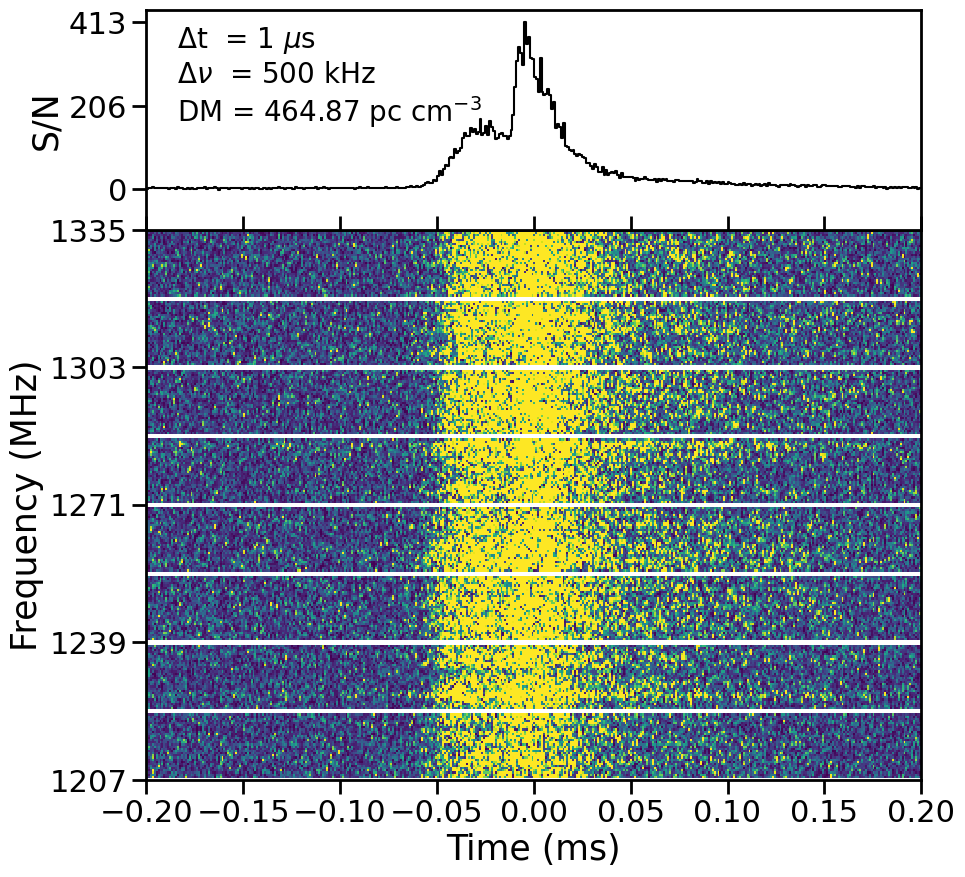

In [31]:
burst_list = ['/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM46487_cor_Wb.fil']
waterfaller_maker(burst=burst_list, DM=464.87, dededisp=-464.85)

the extent of the data is: [-339.8, 428.20000000000005, 1207.0, 1335.0]
loading in the data
de-de-dispersing to DM zero using -464.86 pc/cc
de-dispersing to 464.854 pc/cc
Correcting for the bandpass
downsample factors are: time:1 and freq:1
Masking subband edges
bandwidth is: 128.0 . Number of channels: 256 . First subband array:  [ 0 31]
Subband edges:  32
plot_name: p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb_0.2ms


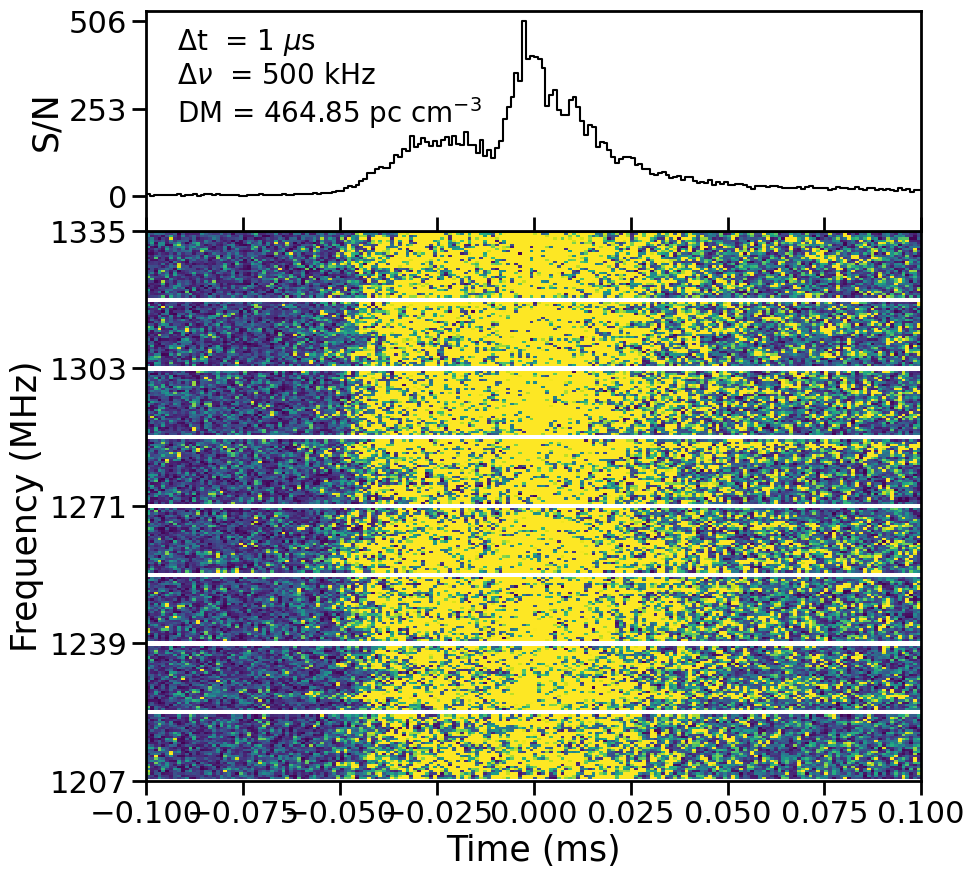

In [64]:
burst_list = ['/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb.fil']
waterfaller_maker(burst=burst_list, DM=464.854, dededisp=-464.86)

In [41]:
def de_dedisp_sn_maximizer(dededisp):
    """
    The input burst is already dedisped by SFXC
    Will de-disperse the burst by giving a negative DM
    """

    burst = your.Your('/data1/omar/sfxc/frb240619d/p55025_28/p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb.fil')
    header_dict = frb_functions.your_header_to_dict(burst)

    tsamp = header_dict['tsamp']
    nbins = header_dict['nspectra']
    freqs = header_dict["freqs"]
    
    #time increasing, freq decreasing
    print("loading in the data")
    d = frb_functions.get_data(burst,nstart=0, nsamp=nbins, npoln=1)
    I_ts = np.mean(d, axis=0)
    I_ts_peak_idx = np.argmax(I_ts)
    dm = dededisp
    range = 0.25
    dm_list = np.arange(dm-range,dm+range,0.0002)

    time_of_sweep_ms, bin_sweep = frb_functions.calc_sweep(chans=burst.chan_freqs,
                                                           tsamp=tsamp,
                                                           dm = dededisp + range)

    d = d[:, int(I_ts_peak_idx - bin_sweep) : int(I_ts_peak_idx + bin_sweep)] 
    I_ts = np.mean(d, axis=0)
    I_ts_peak_idx = np.argmax(I_ts)
    
    print("de-de-dispersing")
    stokes_i_dd = frb_functions.correct_bandpass(d)
    stokes_i_dd = frb_functions.dedisperse(stokes_i_dd,dededisp*-1,freqs,tsamp) 
    print("dedispersing loop started")
    max_sn = []
    
    for dm_dedisp in tqdm(dm_list):
        
        stokes_i = frb_functions.dedisperse(stokes_i_dd,dm_dedisp,freqs,tsamp)
        
        #make profile
        prof = np.mean(stokes_i,axis=0)
        stokes_i_normprof = frb_functions.normalize_1d(prof)
    
        stokes_i_normprof = stokes_i_normprof[I_ts_peak_idx - 1000 : I_ts_peak_idx + 1000] #hardcoded
        sn_peak = np.max(stokes_i_normprof)
        max_sn.append(sn_peak)

    df = pd.DataFrame(data = {"DM":dm_list,\
                              "SN":max_sn})

    name = header_dict["basename"] + f"_{len(dm_list)}_dmtrials"
    print(name)
    df.to_csv(f"{name}_46486.csv",header=True, index=True)

    return df

In [42]:
#This was already run a while ago :) 
df_dm_trials = de_dedisp_sn_maximizer(dededisp=464.86)

loading in the data
The duration of the sweep is: 0.241 seconds
The duration of the sweep is: 240.896 milliseconds
The duration of the sweep is: 240896.272 mircoseconds
This corresponds to 240897 time-bins.
de-de-dispersing
dedispersing loop started


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2500/2500 [39:57<00:00,  1.04it/s]


p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb_2500_dmtrials


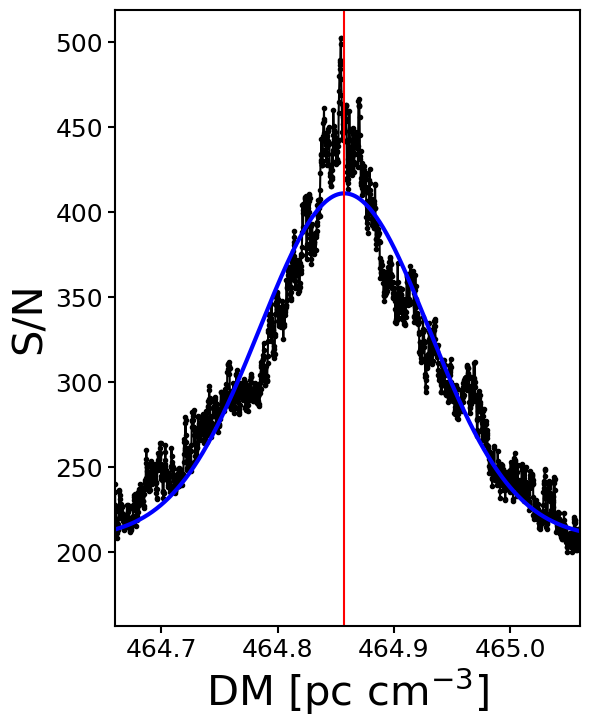

max 464.8544000000081
[2.02893207e+02 4.64857257e+02 7.29856771e-02 2.08081193e+02]
gerr [1.03845173e+00 3.66973163e-04 5.28961739e-04 7.60711339e-01]
464.857 0.004


In [53]:
def sn_vs_dm_1peak(csv):

    df = pd.read_csv(csv, sep=",", header=0, index_col=0)

    #Filter on the DM grid that has to be fitted, we don't want to take into account a wider dm-range 
    #df_filter = df[(df['DM'] > 219.65) & (df['DM'] < 219.8)] 
    sn_filter = df["SN"].values
    dm_filter = df["DM"].values

    poptc,pcovc=curve_fit(gaus, dm_filter, sn_filter, p0=[200,464.87,0.1,200], maxfev=10000)
    
    #Retrieving the entire grid space from the df
    sn_range = df["SN"].values 
    dm_range = df["DM"].values 
    
    ##Figure
    fig,ax=plt.subplots(figsize=(6,8))
    
    #Plotting the whole range
    plt.plot(dm_range, sn_range,'.',color='k',ls='-')
    
    #Plotting only the gaussian
    dm_space = np.linspace(dm_filter[0], dm_filter[-1], 10000)
    plt.plot(dm_space,gaus(dm_space,*poptc),color='b',lw=3,label='B128-Wb')
    
    plt.axvline(poptc[1],color='red')
    #plt.axvline(poptc[1]+poptc[2]/np.sqrt(len(dm_range)),color='red',ls='--',alpha=0.45)
    #plt.axvline(poptc[1]-poptc[2]/np.sqrt(len(dm_range)),color='red',ls='--',alpha=0.45)
    
    for axis in ['top', 'bottom', 'left', 'right']:
        ax.spines[axis].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=18, width=1.5, length=5)
        
    plt.xlabel(r'DM [pc cm$^{-3}]$',size=30)
    plt.ylabel('S/N',size=30)
    #plt.ylim(18.2,21)
    dm = 464.86
    offset = 0.2
    plt.xlim(dm-offset,dm+offset)
    
    # plt.legend(fontsize=14)
    # plt.savefig('snvdm_wb_p.pdf',dpi=300)
    plt.show()
    
    print(f'max {dm_range[np.argmax(sn_range)]}')
    print(f"{poptc}")
    print(f'gerr {np.sqrt(np.diag(pcovc))}')
    print(f'{np.round(poptc[1],3)} {np.round(3*poptc[2]/np.sqrt(len(dm_range)),3)}')
    
    return

sn_vs_dm_1peak(csv="p55025_28_1us_500KHz_StokesI_DM46486_cor_Wb_2500_dmtrials_46486.csv")

In [66]:
frb_functions.calc_sweep(chans=[1200,1300],dm=465,tsamp=0.1)

The duration of the sweep is: 0.198 seconds
The duration of the sweep is: 198.211 milliseconds
The duration of the sweep is: 198210.530 mircoseconds
This corresponds to 2 time-bins.


(198.21052976175875, 2)